 ### Part 2 · Clean the data and build a baseline
 Goal: prepare the data correctly and set a reference score that every later model must beat.

## 2.1 Split

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

SEED = 42

df = fetch_openml(name='adult', version=2, as_frame=True).frame
y = (df['class'] == '>50K').astype(int)
X = df.drop(columns=['class'])

numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(exclude='number').columns.tolist()
X[categorical_cols] = X[categorical_cols].astype(object)  # avoids imputer problems with the category dtype

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED) #0.2 for 20%
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(39073, 14) (9769, 14)
0.23927008420136667 0.23932848807452145


80% training (39,073 rows) and 20% test (9,769 rows). In both parts 23.9% of people earn >50K. From this point the test set is not used until the final evaluation in Part 3, step 4.

## 2.2 Pipeline

In [38]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())])
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)], sparse_threshold=0)

Numeric columns: median imputation, then standardisation. Categorical columns: most-frequent imputation, then one-hot encoding with `handle_unknown='ignore'`, so a category that appears only in the test data becomes all zeros instead of causing an error. A `ColumnTransformer` applies the right pipelines to the right types of columns, and `sparse_threshold=0` makes the output a dense array (required by `HistGradientBoostingClassifier`). After preprocessing, the 14 raw columns become 105 features.

The preprocessor is only a recipe at this point. It learns medians, means and categories when it is fitted inside a pipeline.

## 2.3 Data leakage
Data leakage happens when information from the test data influences training, so the test score looks better than it will be on new data. For example, if I computed the median or the mean for imputation and scaling on the whole dataset before splitting, the training process would already “know” something about the test rows. In my code I split first, and the preprocessing is inside a Pipeline, so fit only sees training data. During cross-validation the pipeline is refitted inside each fold, so the validation part of each fold is never used to compute medians, means or categories.

## 2.4 Baselines

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def evaluate(name, model):
    pipe = Pipeline([('prep', preprocessor), ('clf', model)]) # preprocessing fitted only on the training folds
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {m: res[f'test_{m}'].mean() for m in scoring}
    row['model'] = name
    return row

baseline_results = (pd.DataFrame([evaluate('Dummy (majority)', DummyClassifier(strategy='most_frequent')),
                                evaluate('Logistic regression', LogisticRegression(max_iter=1000, random_state=SEED)),])
                                .set_index('model').round(3))

baseline_results

C:\Users\Diana\PycharmProjects\ML-census-income\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Diana\PycharmProjects\ML-census-income\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Diana\PycharmProjects\ML-census-income\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy (majority),0.761,0.000,0.000,0.000,0.500
Logistic regression,0.851,0.732,0.597,0.658,0.906



The dummy always predicts <=50K, so its accuracy equals the majority share (76.1%) from Part 1. This is the number every model has to beat. Its precision is 0 because it never predicts >50K (sklearn warns about this, but we'll ignore it). Logistic regression is clearly better: ROC AUC 0.906 and F1 0.658.

## 2.5 Why accuracy alone is a weak metric here

About 76% of people earn <=50K, so a model that always predicts <=50K gets 76% accuracy without learning anything (the dummy above has recall 0). Accuracy hides how the model performs on the minority class (>50K), so I also report precision, recall, F1 and ROC AUC.

# Part 3 · Compare models properly
Goal: choose a model using evidence, not intuition.

## 3.1

In [40]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    'Logistic regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random forest': RandomForestClassifier(random_state=SEED, n_jobs=-1), #n_jobs=-1 lets the forest use all CPU cores
    'Gradient boosting': HistGradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'f1'])
    rows.append({
        'model': name,
        'ROC AUC mean': res['test_roc_auc'].mean(),
        'ROC AUC std': res['test_roc_auc'].std(),
        'F1 mean': res['test_f1'].mean(),
        'F1 std': res['test_f1'].std(),})

cv_results = pd.DataFrame(rows).set_index('model').round(3)
cv_results

,ROC AUC mean,ROC AUC std,F1 mean,F1 std
model,,,,
Logistic regression,0.906,0.004,0.658,0.010
Random forest,0.901,0.004,0.665,0.009
Gradient boosting,0.928,0.002,0.708,0.008


All three use the same preprocessing. Gradient boosting is best on both metrics, and its lead (+0.022 ROC AUC, +0.043 F1) is about five times the standard deviation, so it is not random noise. Logistic regression and the random forest are tied: their ROC AUC differs by 0.005, which is close to one standard deviation. Gradient boosting also has the smallest standard deviation, so it is the most stable. I chose it for tuning.

## 3.2

## 3.3

I tuned two hyperparameters of gradient boosting with `GridSearchCV` (5-fold CV, scoring ROC AUC, training data only): `learning_rate` in {0.05, 0.1} and `max_depth` in {3, None}. That is 4 combinations and 20 fits.

In [41]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('prep', preprocessor),
                ('clf', HistGradientBoostingClassifier(random_state=SEED))])
# the same "cleaning, then model" pipeline. tuning happens on the whole pipeline, so no leakage

param_grid = {f'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [3, None]}
# 'clf__' means the setting belongs to the step named clf. 2*2 = 4 combos

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='roc_auc', n_jobs=1)
# cv=cv reuses 5-fold rule. scoring='roc_auc' is the metric that picks the winner
# 4 combinations * 5 folds = 20 fits

grid.fit(X_train, y_train) # training only

print(grid.best_params_)
print(round(grid.best_score_, 3))

tuning_results = (pd.DataFrame(grid.cv_results_)
                  [['param_clf__learning_rate', 'param_clf__max_depth', 'mean_test_score', 'std_test_score']]
                  .sort_values('mean_test_score', ascending=False)
                  .round(4))
tuning_results

{'clf__learning_rate': 0.1, 'clf__max_depth': None}
0.928


,param_clf__learning_rate,param_clf__max_depth,mean_test_score,std_test_score
3,0.10,None,0.9276,0.0024
1,0.05,None,0.9262,0.0024
2,0.10,3,0.9199,0.0032
0,0.05,3,0.9130,0.0033


The best combination (0.1, None) is the same as the library default, so tuning gave no gain (0.928 before and after). Limiting the depth to 3 hurt clearly (about 0.920 and 0.913), so shallow trees underfit. The learning rate hardly matters: the two values differ by 0.0014, which is less than the standard deviation (0.0024). The grid is small on purpose, and a larger search might find a small improvement.

{'accuracy': 0.875, 'precision': 0.785, 'recall': 0.66, 'f1': 0.717, 'roc_auc': 0.929}


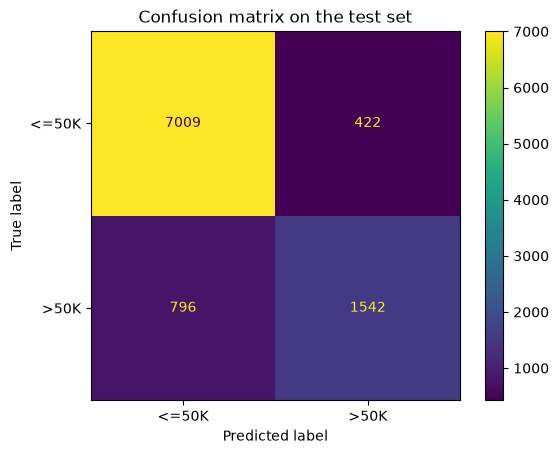

In [42]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test) # 0 or 1 for each test person. pipeline cleans X_test with the statistics learned from training
y_proba = best_model.predict_proba(X_test)[:, 1] # models probability of ">50K" for each person. ROC AUC does not use 0 nor 1

test_scores = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, y_proba)}

print({k: round(v, 3) for k, v in test_scores.items()})

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot()
plt.title('Confusion matrix on the test set')
plt.show()

## 3.4

The test ROC AUC (0.929) is almost identical to the CV score (0.928), and the test F1 (0.717) is close to the CV F1 (0.708). So there is no sign of overfitting to the training data, and the cross-validation estimate was honest. The small gap is within the standard deviation, so it's forgivable.



The confusion matrix shows 7,009 correct <=50K predictions, 422 false alarms (predicted >50K, really <=50K), 796 missed high earners, and 1,542 correct >50K predictions. Missing a high earner is more common than a false alarm, which is why recall (0.66) is lower than precision (0.785).

I did not retune anything after seeing the test score.

## 3.5 Permutation importance


           feature  importance     std
5   marital-status      0.0942  0.0027
10    capital-gain      0.0624  0.0015
0              age      0.0448  0.0023
4    education-num      0.0320  0.0013
11    capital-loss      0.0130  0.0010
12  hours-per-week      0.0122  0.0014
6       occupation      0.0104  0.0009
7     relationship      0.0025  0.0003
1        workclass      0.0024  0.0003
9              sex      0.0017  0.0003
13  native-country      0.0010  0.0003
8             race      0.0008  0.0003
2           fnlwgt      0.0007  0.0003
3        education      0.0002  0.0001


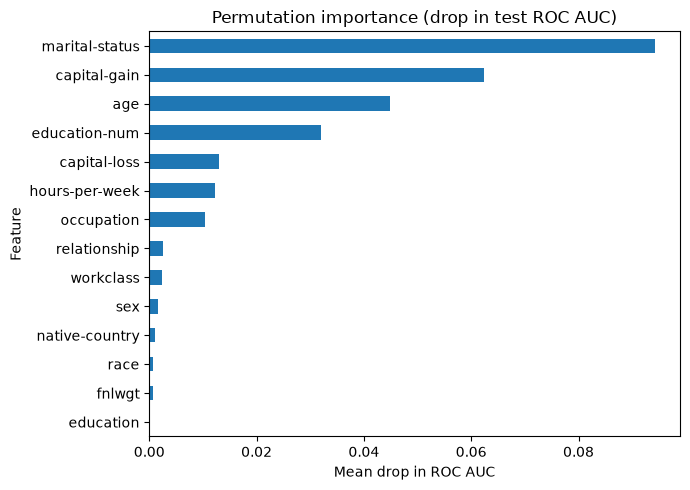

In [43]:
from sklearn.inspection import permutation_importance

# best_model is the full pipeline, so shuffling a raw column also shuffles all its one-hot columns together
perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=SEED, n_jobs=1)
# n_repeats=5: shuffle each column 5 times and average, so the result is less random

importance = (pd.DataFrame({'feature': X_test.columns,
                            'importance': perm.importances_mean,
                            'std': perm.importances_std})
                            .sort_values('importance', ascending=False))
print(importance.round(4))

importance.sort_values('importance').plot(kind='barh', x='feature', y='importance', legend=False, figsize=(7, 5))
plt.title('Permutation importance (drop in test ROC AUC)')
plt.xlabel('Mean drop in ROC AUC')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


I shuffled one original column at a time in the test data and measured the drop in ROC AUC (5 repeats). This is analysis only, and nothing was retuned from it. The most important features are marital-status (drop 0.094), capital-gain (0.062), age (0.045) and education-num (0.032). Features that hardly matter are fnlwgt (0.0007), native-country (0.0010), race (0.0008) and education (0.0002).

This matches my expectations from Part 1: marital status, capital gain, education and age were the strongest patterns in the plots, and fnlwgt (a sampling weight) and native-country (91% United-States) looked useless. `education` is near zero because it duplicates `education-num`, and the model uses the numeric one.

In [44]:
results = X_test.copy()
results['true'] = y_test.values
results['pred'] = y_pred
results['proba'] = y_proba # models probability of >50K

errors = results[results['true'] != results['pred']]
fn = errors[errors['true'] == 1] # missed high earners (false negatives)
fp = errors[errors['true'] == 0] # false alarms (false positives)
tp = results[(results['true'] == 1) & (results['pred'] == 1)]
tn = results[(results['true'] == 0) & (results['pred'] == 0)]
print('false negatives:', len(fn), '| false positives:', len(fp))

# 5 concrete examples: the 3 most confident misses and the 2 most confident false alarms
examples = pd.concat([fn.nsmallest(3, 'proba'), fp.nlargest(2, 'proba')])
examples[['sex','age', 'education', 'occupation', 'marital-status', 'hours-per-week',
          'capital-gain', 'true', 'pred', 'proba']].round(2)

false negatives: 796 | false positives: 422


,sex,age,education,occupation,marital-status,hours-per-week,capital-gain,true,pred,proba
48495,Male,22,5th-6th,Handlers-cleaners,Never-married,40,0,1,0,0.00
28811,Female,39,HS-grad,Adm-clerical,Never-married,40,0,1,0,0.01
36372,Male,27,HS-grad,Transport-moving,Never-married,38,0,1,0,0.01
45268,Male,57,Assoc-voc,Prof-specialty,Married-civ-spouse,45,0,0,1,0.97
11265,Female,38,Assoc-voc,Other-service,Married-civ-spouse,40,0,0,1,0.96


## 3.6 Error analysis

The model made 1,218 mistakes on the test set: 796 false negatives (missed high earners) and 422 false positives. The table above shows five examples: the three most confident misses and the two most confident false alarms.

What the errors have in common: All false negatives fall into some same categories - roughly same amount of hours per week, zero capital gain.

What I would try next: lower the decision threshold, because recall is only 0.66 and the cost of missing a high earner may be higher than a false alarm [only if you pick this]; use class weights; tune a larger grid; or add features such as interactions between age, education and hours.

# Part 4 · A small neural network in PyTorch

Goal: write a training loop yourself and see how a neural network compares with the classical models.

Seed: `42`

## 4.1

In [45]:
import copy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

torch.manual_seed(SEED)
np.random.seed(SEED)

# validation split
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

prep = clone(preprocessor)
X_tr_np = prep.fit_transform(X_tr) # learn medians/means/categories from X_tr
X_val_np = prep.transform(X_val) # apply to validation (no learning)
X_te_np = prep.transform(X_test) # apply to test (also no learning)

def to_X(a):
    a = a.toarray() if hasattr(a, 'toarray') else a   # sparse into dense, just in case
    return torch.tensor(np.asarray(a), dtype=torch.float32)

def to_y(s):
    return torch.tensor(s.values, dtype=torch.float32).unsqueeze(1)   # shape (n, 1)

Xtr_t, ytr_t = to_X(X_tr_np), to_y(y_tr)
Xval_t, yval_t = to_X(X_val_np), to_y(y_val)
Xte_t = to_X(X_te_np)
print('Shapes:', Xtr_t.shape, Xval_t.shape, Xte_t.shape)

Shapes: torch.Size([31258, 105]) torch.Size([7815, 105]) torch.Size([9769, 105])




I took a validation set (20% of the training data): 31,258 rows for training and 7,815 for validation. The preprocessing is fitted on these 31,258 rows only, then applied to the validation and test data. The test set (9,769 rows) is not used until step 4.6. The data is dense (`sparse_threshold=0`), and the tensors are `float32` with shapes (31258, 105), (7815, 105) and (9769, 105).

## 4.2

In [46]:
# NETWORK
class MLP(nn.Module):
    def __init__(self, n_in, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(32, 1))

    def forward(self, x):
        return self.net(x)

# training loop by hand
def train_model(model, epochs=30, lr=1e-3, weight_decay=0.0, patience=None, batch_size=256):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True, generator=g)

    history = {'train': [], 'val': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        history['train'].append(running / len(loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xval_t), yval_t).item()
        history['val'].append(val_loss)

        if val_loss < best_val:
            best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        if patience and bad_epochs >= patience:
            print(f'Early stopping at epoch {epoch + 1}')
            break

    if patience:
        model.load_state_dict(best_state)   # going back to the best epoch
    return history

# plain network (no regularisation)
torch.manual_seed(SEED)
model_plain = MLP(Xtr_t.shape[1])
hist_plain = train_model(model_plain, epochs=30)

# regularised network: dropout + weight decay + early stopping
torch.manual_seed(SEED)
model_reg = MLP(Xtr_t.shape[1], dropout=0.3)
hist_reg = train_model(model_reg, epochs=60, weight_decay=1e-4, patience=5)

# learning curves
def plot_curves(ax, hist, title):
    epochs_axis = range(1, len(hist['train']) + 1)
    ax.plot(epochs_axis, hist['train'], label='train loss')
    ax.plot(epochs_axis, hist['val'], label='validation loss')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('BCE loss')
    ax.legend()

Early stopping at epoch 12


## 4.3

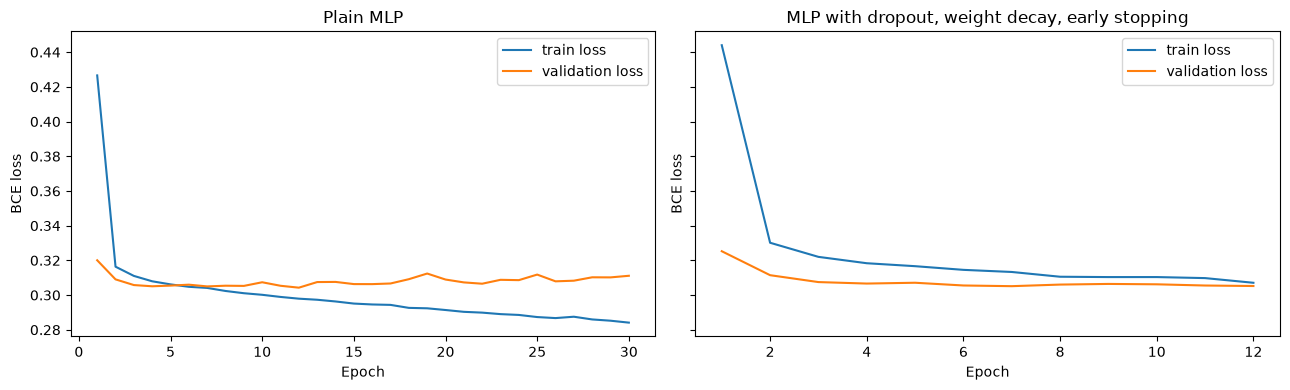

Plain MLP: best validation loss 0.3043 at epoch 12
Plain MLP: validation loss at the last epoch 0.3111
Regularised MLP: best validation loss 0.3051 after 12 epochs
Final network: regularised


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_curves(axes[0], hist_plain, 'Plain MLP')
plot_curves(axes[1], hist_reg, 'MLP with dropout, weight decay, early stopping')
plt.tight_layout()
plt.show()

best_epoch_plain = int(np.argmin(hist_plain['val'])) + 1
print('Plain MLP: best validation loss', round(min(hist_plain['val']), 4), 'at epoch', best_epoch_plain)
print('Plain MLP: validation loss at the last epoch', round(hist_plain['val'][-1], 4))
print('Regularised MLP: best validation loss', round(min(hist_reg['val']), 4),
      'after', len(hist_reg['val']), 'epochs')

# picking the final network by validation loss, then testing it once
plain_val = hist_plain['val'][-1] # the plain model keeps its last-epoch weights
reg_val = min(hist_reg['val']) # the regularised model was restored to its best epoch
final_nn = model_reg if reg_val <= plain_val else model_plain
print('Final network:', 'regularised' if final_nn is model_reg else 'plain')

final_nn.eval()
with torch.no_grad():
    nn_proba = torch.sigmoid(final_nn(Xte_t)).squeeze(1).numpy()
nn_pred = (nn_proba >= 0.5).astype(int)

In [48]:
def score_row(y_true, pred, proba):
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred),
            'roc_auc': roc_auc_score(y_true, proba)}

nn_scores = score_row(y_test, nn_pred, nn_proba)

# final comparison table (test set, same metrics for all models)
rows = {'Gradient boosting (tuned)': test_scores, 'Neural network (MLP)': nn_scores}
for name, model in [('Logistic regression', LogisticRegression(max_iter=1000, random_state=SEED)),
                    ('Random forest', RandomForestClassifier(random_state=SEED))]:
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])
    pipe.fit(X_train, y_train)
    rows[name] = score_row(y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1])

comparison = pd.DataFrame(rows).T.round(3).sort_values('roc_auc', ascending=False)
comparison

,accuracy,precision,recall,f1,roc_auc
Gradient boosting (tuned),0.875,0.785,0.660,0.717,0.929
Neural network (MLP),0.859,0.748,0.619,0.677,0.912
Logistic regression,0.852,0.741,0.589,0.656,0.904
Random forest,0.860,0.743,0.636,0.685,0.904


## 4.6
The chosen network was evaluated once on the test set. Logistic regression and the random forest were fitted on the training set with default settings and only scored on the test set to complete the table below. Nothing was tuned or selected using these scores.

**Is the network better than the best classical model?** No. It is worse than tuned gradient boosting on every metric (ROC AUC 0.912 vs 0.929, F1 0.677 vs 0.717). It is slightly better than logistic regression and the random forest on ROC AUC (0.912 vs 0.904), and about equal to the random forest on F1.

I think this is typical for tabular data: the columns have different meanings and types, there is no spatial or sequential structure for a network to exploit, and about 48,000 rows is modest for one. Tree-based models handle mixed features and sharp thresholds (such as capital gain above zero) with little tuning, and gradient boosting trains in seconds on a CPU. I would use tuned gradient boosting.